# Mosaic Images
Create mosaics from multiple MANGO sites.

In [1]:
import itertools
import numpy as np
import datetime as dt
import h5py
import xarray as xr
import pymap3d as pm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature


Define processed data files to use for mosaic.

In [2]:
filenames = ['MANGO_Data/new_format/blo/greenline/level1/2023/131/mango-blo-greenline-level1-20230511.hdf5',
             'MANGO_Data/new_format/cfs/greenline/level1/2023/131/mango-cfs-greenline-level1-20230511.hdf5',
             'MANGO_Data/new_format/cvo/greenline/level1/2023/131/mango-cvo-greenline-level1-20230511.hdf5',
             'MANGO_Data/new_format/bdr/greenline/level1/2023/131/mango-bdr-greenline-level1-20230511.hdf5',
             'MANGO_Data/new_format/mro/greenline/level1/2023/131/mango-mro-greenline-level1-20230511.hdf5',
             'MANGO_Data/new_format/low/greenline/level1/2023/131/mango-low-greenline-level1-20230511.hdf5']

Read datafiles into xarray.

In [9]:
mango_data = dict()
for fn in filenames:
    with h5py.File(fn, 'r') as h5:
        
        utime = h5['UnixTime'][:]
        time = [dt.datetime.fromtimestamp(ut, tz=dt.timezone.utc) for ut in utime[:,0]]
        
        image = xr.DataArray(h5['ImageData'][:], dims=('time','i','j'), coords={'time':time})
    
        azmt = xr.DataArray(h5['Coordinates/Azimuth'][:], dims=('i','j'))
        elev = xr.DataArray(h5['Coordinates/Elevation'][:], dims=('i','j'))
    
        glat = xr.DataArray(h5['Coordinates/Latitude'][:], dims=('i','j'))
        glon = xr.DataArray(h5['Coordinates/Longitude'][:], dims=('i','j'))

        proj_alt = h5['Coordinates/XYGrid'].attrs['Projection Altitude']

        mask = xr.DataArray(h5['Mask'][:], dims=('i','j'))
        
        name = h5['SiteInfo/Name'][()]
        code = h5['SiteInfo/Code'][()].decode('utf-8')
        instrument = h5['SiteInfo/Instrument'][()]
        coordinates = h5['SiteInfo/GeodeticCoordinates'][:]

    mango_data[code] = xr.Dataset({'image':image, 'glat':glat, 'glon':glon, 'azmt':azmt, 'elev':elev, 'mask':mask, 'alt':proj_alt, 'sitecoords':coordinates})



## Calculate Mosaic Masks

Define a function to calculate the mask between two sites.

In [6]:
RE = 6371.

def calculate_masks(sitelat1, sitelon1, az1, el1, h1, sitelat2, sitelon2, az2, el2, h2):

    # Convert site latitude and longitude to radians
    l1 = np.deg2rad(sitelat1)
    p1 = np.deg2rad(sitelon1)
    l2 = np.deg2rad(sitelat2)
    p2 = np.deg2rad(sitelon2)
    # Differences
    dl = (l2 - l1)
    dp = (p2 - p1)
    
    # Calculate the bearing
    y = np.sin(dp) * np.cos(l2)
    x = np.cos(l1) * np.sin(l2) - np.sin(l1) * np.cos(l2) * np.cos(dp)
    brg1 = np.atan2(y, x)
    
    y = np.sin(-dp) * np.cos(l1)
    x = np.cos(l2) * np.sin(l1) - np.sin(l2) * np.cos(l1) * np.cos(-dp)
    brg2 = np.atan2(y, x)
    
    # Calculate the angular distance
    a = np.sin(dl/2)**2 + np.sin(dp/2)**2 * np.cos(l1) * np.cos(l2)
    psi = 2 * np.asin(np.sqrt(a))
    
    
    # Calculate the masks
    Gam1 = np.deg2rad(az1) - brg1
    Gam2 = np.deg2rad(az2) - brg2
    lam1 = np.deg2rad(el1)
    lam2 = np.deg2rad(el2)
    
    A1 = np.sqrt(1-(RE/(RE+h1))**2*np.cos(lam1)**2)/(RE/(RE+h1)*np.cos(lam1))
    B1 = (A1-np.tan(lam1))/(1+A1*np.tan(lam1))*np.cos(Gam1)
    mask1 = B1 > np.tan(psi/2)
    
    A2 = np.sqrt(1-(RE/(RE+h2))**2*np.cos(lam2)**2)/(RE/(RE+h2)*np.cos(lam2))
    B2 = (A2-np.tan(lam2))/(1+A2*np.tan(lam2))*np.cos(Gam2)
    mask2 = B2 > np.tan(psi/2)

    return mask1, mask2


Create a xarray with the masks for each combination of sites.

In [10]:
site_codes = list(mango_data.keys())
num_site = len(mango_data)
mosaic_mask =  xr.DataArray(np.full((num_site,num_site,500,500), False), dims=('s1','s2','i','j'), coords={'s1':site_codes, 's2':site_codes})

for s1, s2 in itertools.combinations(mango_data.keys(), 2):
    print(s1, s2)

    sitelat1, sitelon1 = mango_data[s1]['sitecoords']
    az1 = mango_data[s1]['azmt']
    el1 = mango_data[s1]['elev']
    alt1 = mango_data[s1]['alt']
    
    sitelat2, sitelon2 = mango_data[s2]['sitecoords']
    az2 = mango_data[s2]['azmt']
    el2 = mango_data[s2]['elev']
    alt2 = mango_data[s2]['alt']
    
    mask1, mask2 = calculate_masks(sitelat1, sitelon1, az1, el1, alt1, sitelat2, sitelon2, az2, el2, alt2)

    mosaic_mask.loc[s1,s2] = mask1.astype(bool)
    mosaic_mask.loc[s2,s1] = mask2.astype(bool)

#mosaic_mask

blo cfs
blo cvo
blo bdr
blo mro
blo low
cfs cvo
cfs bdr
cfs mro
cfs low
cvo bdr
cvo mro
cvo low
bdr mro
bdr low
mro low


## Generate Mosaic Image
Create a mosaic map for a single time.

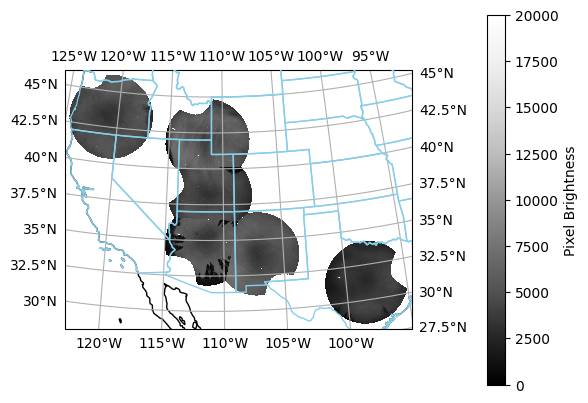

In [11]:
proj = ccrs.Orthographic(central_latitude=42., central_longitude=-111.)
fig, ax = plt.subplots(subplot_kw={'projection':proj})
ax.gridlines(draw_labels=True, zorder=3)
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.STATES, zorder=5, edgecolor='skyblue')

for code, data in mango_data.items():

    # Apply FoV and Mosaic masks
    image = data['image'].where(~data['mask']).where(~mosaic_mask.loc[code].any(dim='s2'))[0]
    
    c = ax.pcolormesh(data['glon'], data['glat'], image, vmin=0, vmax=20000, cmap='Greys_r', transform=ccrs.PlateCarree())

fig.colorbar(c, pad=0.15, label='Pixel Brightness')
plt.show()